In [ ]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [38]:
def threshold_update(img, binimg, T):
  sum1 = np.int32(0)
  sum2 = np.int32(0)
  count1 = 1
  count2 = 1

  for i in range(img.shape[0]):
    for j in range(img.shape[1]):
      if binimg[i][j] == 0:
        sum1 += img[i][j]
        count1 += 1
      else:
        sum2 += img[i][j]
        count2 += 1



  avg1 = sum1/count1
  avg2 = sum2/count2

  T2 = np.int32(avg1 + avg2)/2
  return T2


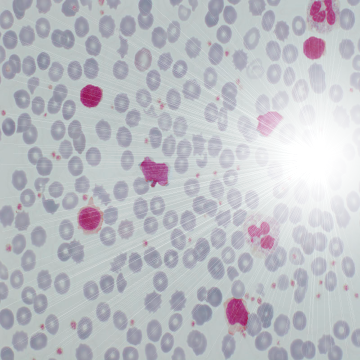

In [39]:
#img = cv2.imread('/content/gdrive/My Drive/ColabIP26/Images/lena256.jpg')
#img = cv2.imread('/content/gdrive/My Drive/ColabIP26/Images/milkdrop.bmp')
img = cv2.imread('/content/gdrive/My Drive/ColabIP26/Images/cell-bright.bmp')
gimg = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
RGB_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
cv2_imshow(gimg)


In [42]:
T1 = 128
T2 = 0
binimg = np.zeros(gimg.shape, dtype=np.uint8)

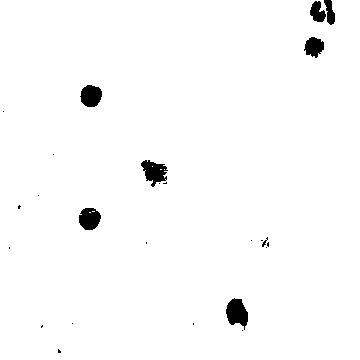

In [53]:
binimg = np.zeros(RGB_img.shape, dtype=np.uint8)

for i in range(RGB_img.shape[0]):
  for j in range(RGB_img.shape[1]):
    if RGB_img[i][j] < T1:
      binimg[i][j] = 0
    else:
      binimg[i][j] = 255

cv2_imshow(binimg)

In [54]:
while True:
  T2 = threshold_update(RGB_img, binimg, T1)

  if(np.abs(T1-T2) < 1):
    for i in range(RGB_img.shape[0]):
      for j in range(RGB_img.shape[1]):
        if RGB_img[i][j] > T2:
          binimg[i][j] = 255
        else:
          binimg[i][j] = 0
    break
  else:
    T1 = T2
    for i in range(RGB_img.shape[0]):
      for j in range(RGB_img.shape[1]):
        if RGB_img[i][j] > T1:
          binimg[i][j] = 255
        else:
          binimg[i][j] = 0


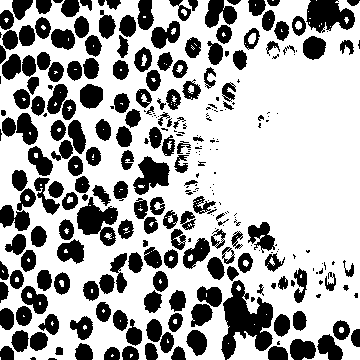

184.0


In [55]:
cv2_imshow(binimg)
print(T2)